# SemRel2024 source and data audit
This notebook examines real human-rated Amharic, Hausa and Kinyarwanda news pairs. It displays aggregate counts/distributions only, never source text or raw pair rows. Test input counts and text-connected groups are label-free; target histograms use train/development only.

The initial generated-paraphrase language proposal was rejected during source audit. No generated sentences, translations or pseudo-labels are used.

In [1]:
from pathlib import Path
import sys,json,math,hashlib,time,copy
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib','inline')
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
PROCESSED=ROOT/'data/processed/semrel-lf-v1'
CACHE=ROOT/'data/features/afro-xlmr-v1'
FIGURES=ROOT/'assets/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=3)
    fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def report(name):return json.loads((ROOT/'docs'/name).read_text(encoding='utf-8'))

In [2]:
from src.config import LANGUAGES,SOURCE_HASHES,DATA_REVISION
from src.data.components import audit_components
from src.data.make_dataset import sha,pair_key,normalized
splits={s:[json.loads(line) for line in (PROCESSED/(s+'.jsonl')).read_text(encoding='utf-8').splitlines()] for s in ('train','dev','test')}
assert all('target' not in row for row in splits['test'])
counts=pd.DataFrame([{'split':s,'language':lang,'pairs':sum(r['language']==lang for r in rows)} for s,rows in splits.items() for lang in LANGUAGES])
display(counts.pivot(index='language',columns='split',values='pairs'))
print({'source_revision':DATA_REVISION,'official_CSV_hashes':len(SOURCE_HASHES),'test_targets_loaded':False})

split,dev,test,train
language,,,
amh,95,171,992
hau,212,603,1736
kin,79,222,728


{'source_revision': '3c5941ddffdc9d833a5528f49dd13ed9087c0dba', 'official_CSV_hashes': 9, 'test_targets_loaded': False}


In [3]:
audit=json.loads((PROCESSED/'audit.json').read_text(encoding='utf-8'))
copies=pd.DataFrame(audit['languages']).T[['original_train','original_dev','removed_training_pairs','removed_dev_test_pair_copies','remaining_cross_split_pair_overlap']]
display(copies)
for lang in LANGUAGES:
    keys={s:{pair_key(r) for r in rows if r['language']==lang} for s,rows in splits.items()}
    assert keys['train'].isdisjoint(keys['dev']|keys['test'])
    assert keys['dev'].isdisjoint(keys['test'])

,original_train,original_dev,removed_training_pairs,removed_dev_test_pair_copies,remaining_cross_split_pair_overlap
amh,992,95,0,0,0
hau,1736,212,0,0,0
kin,778,102,50,23,0


## Rating distributions and language balance
These are original human scores. Language-balanced loss weights equalize total training contribution without inventing examples.

,language,training_pairs,sum_loss_weight
0,amh,992,1152.000000
1,hau,1736,1151.999878
2,kin,728,1152.000000


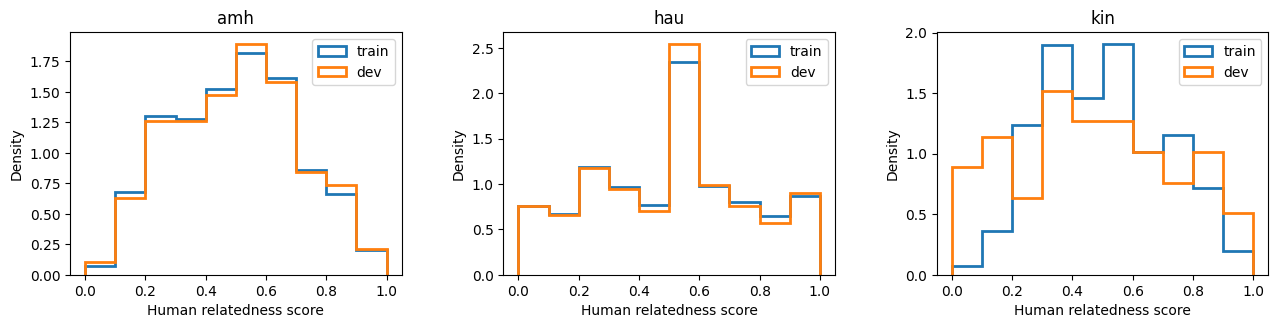

In [4]:
from src.models.train import balanced_weights
train_languages=np.asarray([r['language'] for r in splits['train']])
weights=balanced_weights(train_languages)
display(pd.DataFrame([{'language':lang,'training_pairs':int((train_languages==lang).sum()),'sum_loss_weight':float(weights[train_languages==lang].sum())} for lang in LANGUAGES]))
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
for ax,lang in zip(axes,LANGUAGES):
    for split in ('train','dev'):
        values=[r['target'] for r in splits[split] if r['language']==lang]
        ax.hist(values,bins=np.linspace(0,1,11),density=True,histtype='step',linewidth=2,label=split)
    ax.set(title=lang,xlabel='Human relatedness score',ylabel='Density');ax.legend()
show(fig,'sts_rating_distributions.png')

sentences  median_characters  p95_characters  \
language split                                                 
amh      dev          190               34.5           69.65   
         train       1984               37.0           67.00   
hau      dev          424              109.0          144.85   
         train       3472              108.0          143.00   
kin      dev          158              140.5          189.15   
         train       1456              144.0          190.00   

                median_whitespace_tokens  
language split                            
amh      dev                         8.0  
         train                       9.0  
hau      dev                        20.0  
         train                      20.0  
kin      dev                        20.0  
         train                      21.0

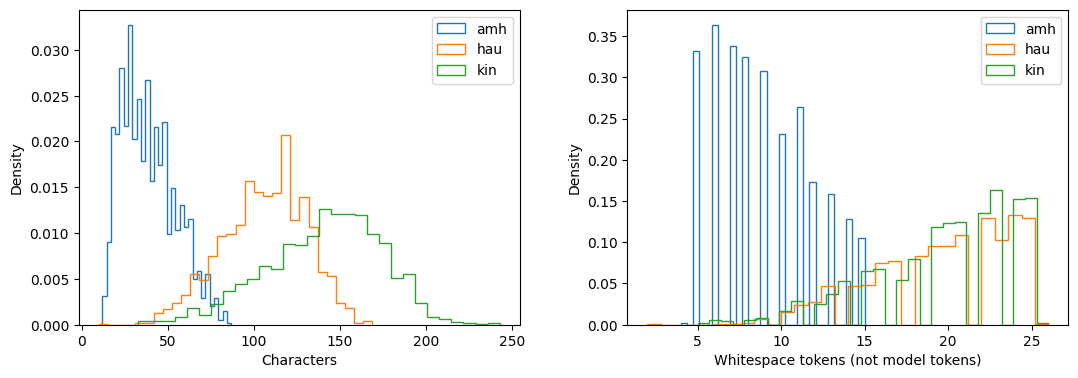

In [5]:
lengths=pd.DataFrame([{'language':r['language'],'split':s,'characters':len(r[key]),'whitespace_tokens':len(r[key].split())} for s in ('train','dev') for r in splits[s] for key in ('sentence1','sentence2')])
display(lengths.groupby(['language','split']).agg(sentences=('characters','size'),median_characters=('characters','median'),p95_characters=('characters',lambda x:x.quantile(.95)),median_whitespace_tokens=('whitespace_tokens','median')))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for lang,block in lengths.groupby('language'):
    axes[0].hist(block['characters'],bins=30,histtype='step',density=True,label=lang)
    axes[1].hist(block['whitespace_tokens'],bins=30,histtype='step',density=True,label=lang)
axes[0].set(xlabel='Characters',ylabel='Density');axes[1].set(xlabel='Whitespace tokens (not model tokens)',ylabel='Density')
for ax in axes:ax.legend()
show(fig,'sts_text_length_audit.png')

## Connected sentence components
Pair-copy removal does not produce sentence-disjoint evaluation. Transitive sentence reuse connects many Hausa rows; shared sentences alone do not prove copied pair-target leakage.

,components,sentence_nodes,largest_component_sentence_nodes,cross_split_components
amh,1240,2498,4,6
hau,403,2753,1364,131
kin,826,1851,10,72


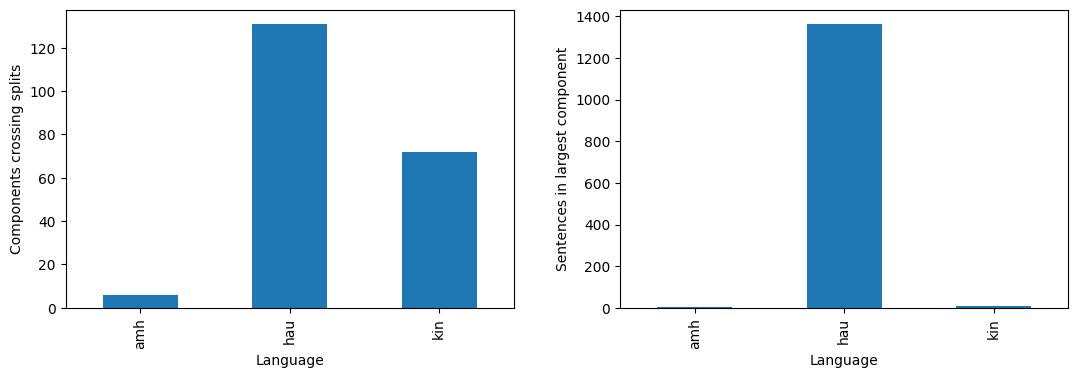

In [6]:
groups,component_audit=audit_components(splits)
component_frame=pd.DataFrame(component_audit['languages']).T
display(component_frame[['components','sentence_nodes','largest_component_sentence_nodes','cross_split_components']])
fig,axes=plt.subplots(1,2,figsize=(11,4))
component_frame['cross_split_components'].plot.bar(ax=axes[0]);axes[0].set(ylabel='Components crossing splits',xlabel='Language')
component_frame['largest_component_sentence_nodes'].plot.bar(ax=axes[1]);axes[1].set(ylabel='Sentences in largest component',xlabel='Language')
show(fig,'sts_sentence_component_audit.png')

In [7]:
receipt=report('encoder-v2-receipt.json')
display(pd.DataFrame(receipt['splits']).T[['rows','sentences','truncated_sentences']])
display(pd.DataFrame([{'encoder':receipt['model'],'revision':receipt['revision'],'pooling':receipt['pooling'],'weight_SHA256':receipt['weight_sha256'],'missing_keys':receipt['loading']['missing_keys'],'mismatched_keys':receipt['loading']['mismatched_keys']}]))
assert all(block['truncated_sentences']==0 for block in receipt['splits'].values())

,rows,sentences,truncated_sentences
train,3456,5582,0
dev,386,742,0
test,996,1809,0


,encoder,revision,pooling,weight_SHA256,missing_keys,mismatched_keys
0,Davlan/afro-xlmr-base,25f27299c247a6b73a767bd82d12444138b19337,attention-mask mean; no pooler; L2,{'model.safetensors': 'f73b04316c9c2e76fcb2139...,[],[]


All encoded sentences fit the 128-token limit. Six actual text inputs reproduced exactly in the encoder smoke. The weights are MLM adapted rather than similarity trained; upstream pretraining overlap with news text is unknown. Clustered uncertainty describes this corpus, not independent document/location transfer.